<a href="https://colab.research.google.com/github/abiyuneyadti24/Analisis_Kematangan_Pisang_HSV/blob/main/Operasi_Geometri_Citra_Digital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1- Import Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, transform, img_as_ubyte
from scipy.ndimage import shift

print("Library berhasil diimpor!")

Library berhasil diimpor!


2- Mengambil dan menampilkan citra asli

Saving WhatsApp Image 2026-10-24 at 19.27.47.jpeg to WhatsApp Image 2026-10-24 at 19.27.47.jpeg


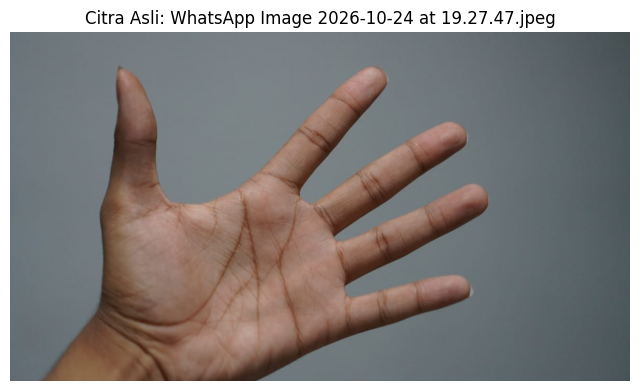

Nama file         : WhatsApp Image 2026-10-24 at 19.27.47.jpeg
Ukuran citra      : (675, 1200, 3)
Tinggi citra      : 675 piksel
Lebar citra       : 1200 piksel
Jumlah kanal      : 3
Tipe data         : uint8


In [ ]:
# Mengimpor pustaka yang diperlukan untuk mengunggah dan membaca gambar
from google.colab import files
from PIL import Image
import io

# Mengunggah gambar dari komputer
uploaded = files.upload()

# Mengambil nama file gambar
nama_file = list(uploaded.keys())[0]

# Membaca gambar yang diunggah
citra_asli = Image.open(
    io.BytesIO(uploaded[nama_file])
)

# Mengubah gambar menjadi format RGB
citra_asli = citra_asli.convert("RGB")

# Mengubah gambar menjadi array NumPy
citra_asli = np.array(citra_asli)

# Menampilkan gambar asli
plt.figure(figsize=(8, 6))
plt.imshow(citra_asli)
plt.title("Citra Asli: " + nama_file)
plt.axis("off")
plt.show()

# Menampilkan informasi citra
print("Nama file         :", nama_file)
print("Ukuran citra      :", citra_asli.shape)
print("Tinggi citra      :", citra_asli.shape[0], "piksel")
print("Lebar citra       :", citra_asli.shape[1], "piksel")
print("Jumlah kanal      :", citra_asli.shape[2])
print("Tipe data         :", citra_asli.dtype)

3- Operasi translasi

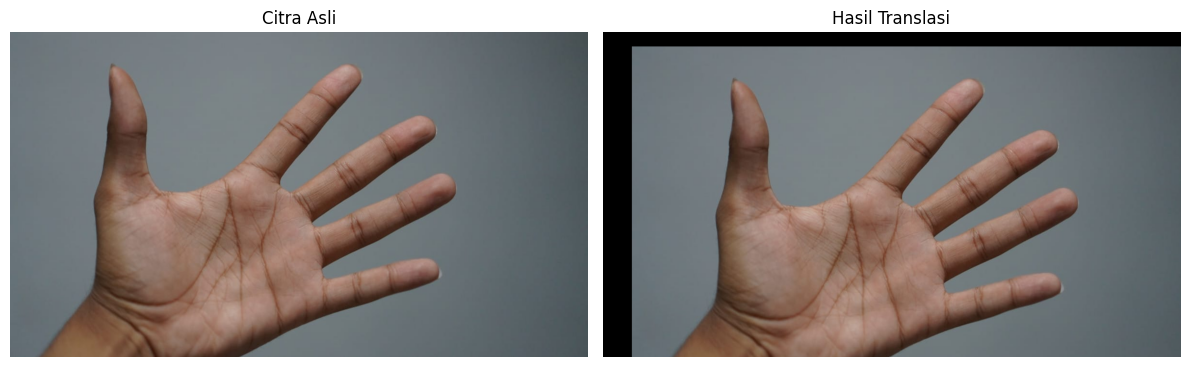

In [ ]:
# Menggeser citra 60 piksel ke kanan
# dan 30 piksel ke bawah
# Kita menggunakan shift=(30, 60, 0) karena citra memiliki 3 dimensi (RGB)
citra_translasi = shift(
    citra_asli,
    shift=(30, 60, 0),
    mode="constant",
    cval=0
).astype(np.uint8)

# Menampilkan perbandingan
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(citra_asli, cmap="gray")
ax[0].set_title("Citra Asli")

ax[1].imshow(citra_translasi, cmap="gray")
ax[1].set_title("Hasil Translasi")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

4- Oprasi Scaling (Perubahan Ukuran)

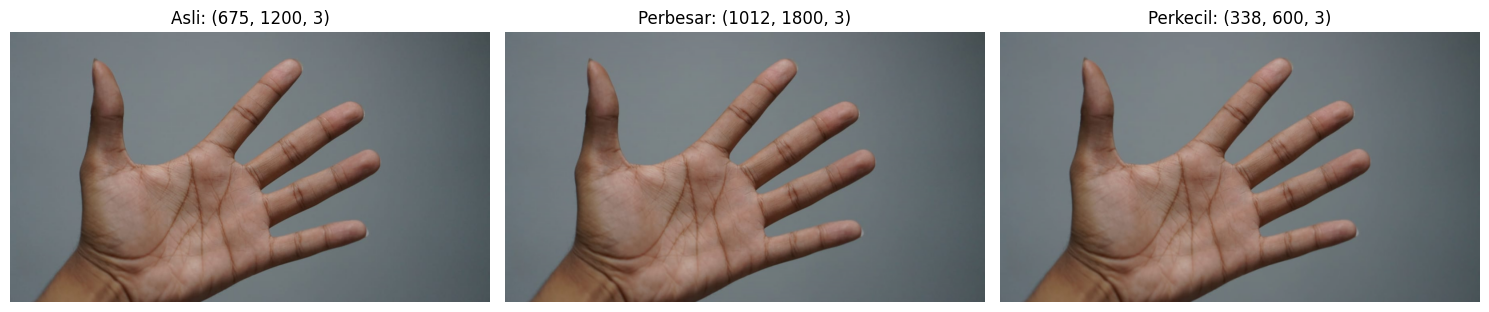

In [ ]:
# Memperbesar citra 1,5 kali dengan menambahkan channel_axis=-1
citra_perbesar = transform.rescale(
    citra_asli,
    scale=1.5,
    order=1,
    preserve_range=True,
    anti_aliasing=True,
    channel_axis=-1
).astype(np.uint8)

# Memperkecil citra menjadi 0,5 kali dengan menambahkan channel_axis=-1
citra_perkecil = transform.rescale(
    citra_asli,
    scale=0.5,
    order=1,
    preserve_range=True,
    anti_aliasing=True,
    channel_axis=-1
).astype(np.uint8)

# Menampilkan hasil
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(citra_asli, cmap="gray")
ax[0].set_title(f"Asli: {citra_asli.shape}")

ax[1].imshow(citra_perbesar, cmap="gray")
ax[1].set_title(f"Perbesar: {citra_perbesar.shape}")

ax[2].imshow(citra_perkecil, cmap="gray")
ax[2].set_title(f"Perkecil: {citra_perkecil.shape}")

for a in ax:
  a.axis("off")

plt.tight_layout()
plt.show()


5- Operasi notasi

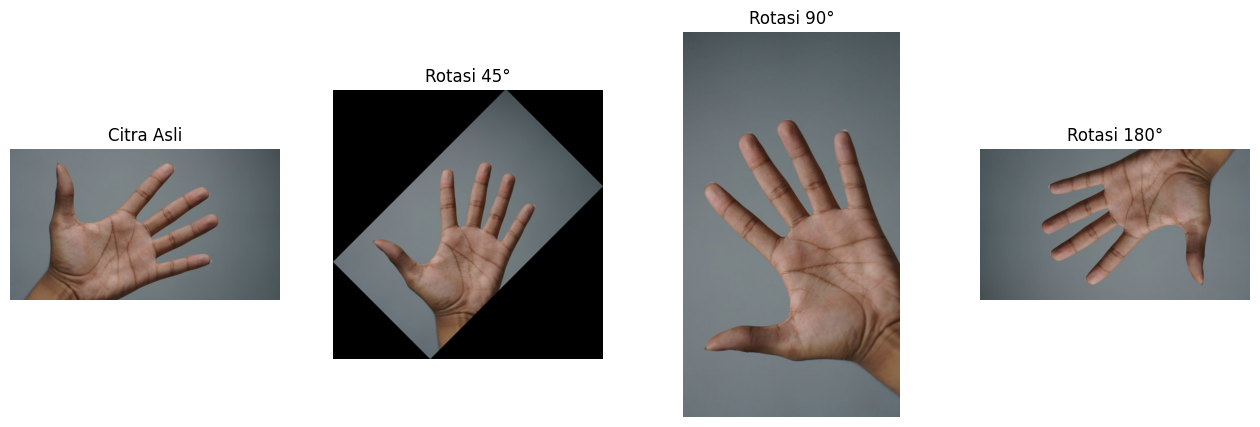

In [ ]:
# Membuat hasil rotasi
citra_rotasi_45 = transform.rotate(
    citra_asli, angle=45,
    resize=True, preserve_range=True
).astype(np.uint8)

citra_rotasi_90 = transform.rotate(
    citra_asli, angle=90,
    resize=True, preserve_range=True
).astype(np.uint8)

citra_rotasi_180 = transform.rotate(
    citra_asli, angle=180,
    resize=True, preserve_range=True
).astype(np.uint8)

# Menampilkan hasil rotasi
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

gambar = [
    citra_asli,
    citra_rotasi_45,
    citra_rotasi_90,
    citra_rotasi_180
]

judul = [
    "Citra Asli",
    "Rotasi 45°",
    "Rotasi 90°",
    "Rotasi 180°"
]

for a, img, title in zip(ax, gambar, judul):
    a.imshow(img, cmap="gray")
    a.set_title(title)
    a.axis("off")

6- Operasi refleksi (pencerminan)

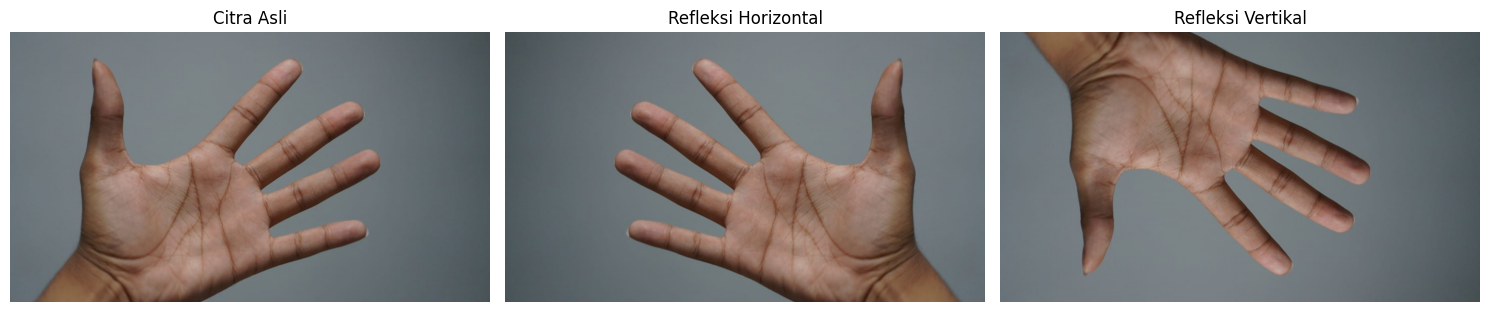

In [ ]:
# Refleksi horizontal: membalik kiri dan kanan
citra_horizontal = np.fliplr(citra_asli)

# Refleksi vertikal: membalik atas dan bawah
citra_vertikal = np.flipud(citra_asli)

# Menampilkan hasil
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(citra_asli, cmap="gray")
ax[0].set_title("Citra Asli")

ax[1].imshow(citra_horizontal, cmap="gray")
ax[1].set_title("Refleksi Horizontal")

ax[2].imshow(citra_vertikal, cmap="gray")
ax[2].set_title("Refleksi Vertikal")

for a in ax:
  a.axis("off")

plt.tight_layout()
plt.show()

7- Menggabungkan bebrapa operasi geometri

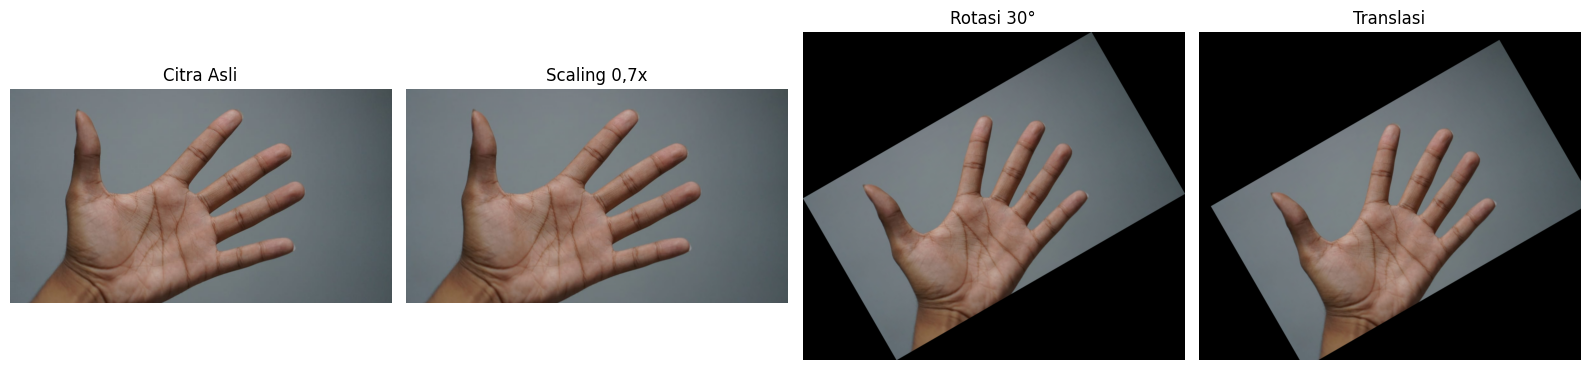

In [ ]:
# 1. Memperkecil citra dengan menambahkan channel_axis=-1
langkah_1 = transform.rescale(
    citra_asli,
    scale=0.7,
    order=1,
    preserve_range=True,
    anti_aliasing=True,
    channel_axis=-1
).astype(np.uint8)

# 2. Memutar citra 30 derajat
langkah_2 = transform.rotate(
    langkah_1,
    angle=30,
    resize=True,
    preserve_range=True
).astype(np.uint8)

# 3. Menggeser citra dengan menggunakan shift 3D (tinggi, lebar, kanal_warna)
langkah_3 = shift(
    langkah_2,
    shift=(20, 30, 0),
    mode="constant",
    cval=0
).astype(np.uint8)

# Menampilkan tahapan transformasi
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

hasil = [
    citra_asli,
    langkah_1,
    langkah_2,
    langkah_3
]

judul = [
    "Citra Asli",
    "Scaling 0,7x",
    "Rotasi 30°",
    "Translasi"
]

for a, img, title in zip(ax, hasil, judul):
    a.imshow(img, cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()